In [1]:
import numpy as np
import matplotlib.pyplot as plt

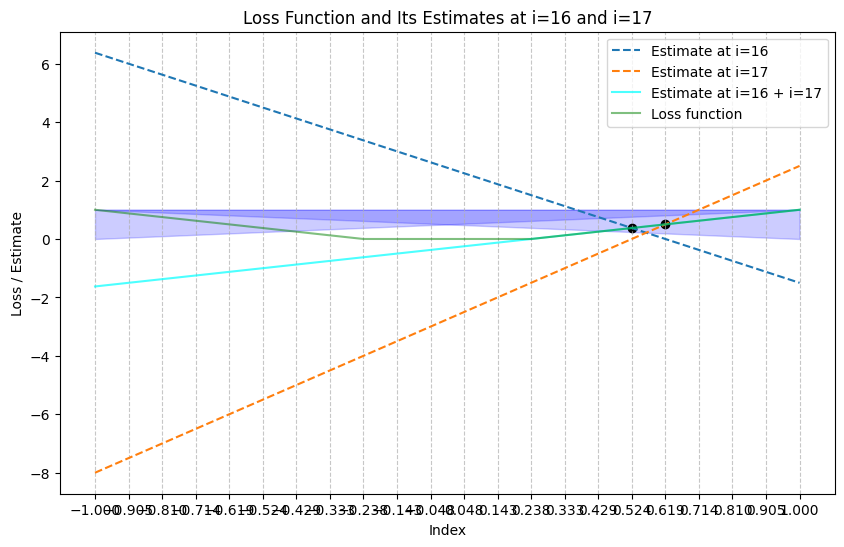

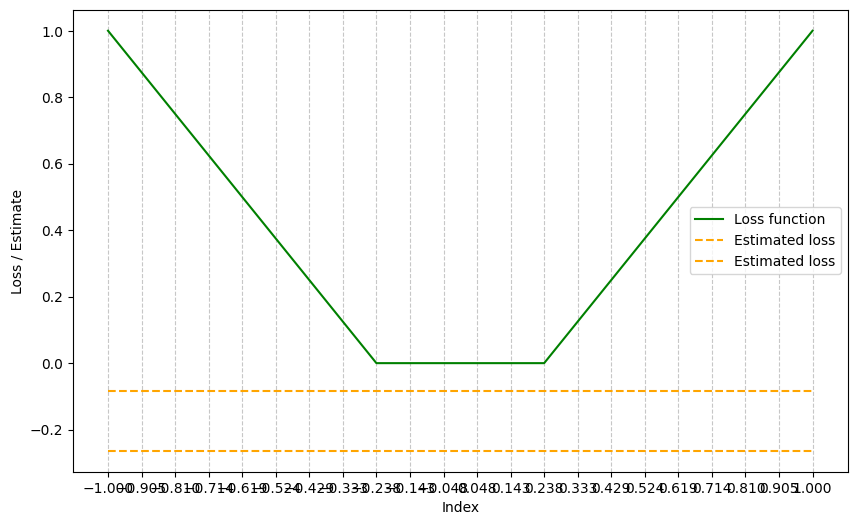

In [6]:
import numpy as np
from IPython.display import display, Math
from matplotlib import pyplot as plt

d = 22
rng = (-1, 1)
C = np.linspace(rng[0], rng[1], d)

inc_base = C * (1/(rng[1] - rng[0])) + 0.5
dec_base = 1 - inc_base

def estimate(y, i, p_i):
    # This function returs an d-dimensional vector that estimates the loss vector at all points
    if i % 2 == 0:
        est = np.zeros(d)
        for j in range(d):
            est[j] = (C[j] - C[i+1])/(C[i] - C[i+1])
            # if y!=1 and C[j] <= (C[i] - y)/(1-y):
            #     est[j] = 0
            # if  y!=1 and C[j] >= (C[i] + y)/(1-y):
            #     est[j] = 0
        return est * y/ (p_i * d)
    else:
        est = np.zeros(d)
        for j in range(d):
            est[j] = (C[i-1] - C[j])/(C[i-1] - C[i])
            # if y!=1 and C[j] <= (C[i] - y)/(1-y):
            #     est[j] = 0
            # if  y!=1 and C[j] >= (C[i] + y)/(1-y):
            #     est[j] = 0
        return est * y / (p_i * d)

# plt.plot(C, estimate(0.9, 10, 1/d), label='Estimate at i=10', color='blue')
# plt.plot(C, estimate(1, 11, 1/d), label='Estimate at i=11', color='red')
# plt.plot(C, estimate(1, 11, 1/d) + estimate(0.9, 10, 1/d), label='Estimate at i=10', color='green')

l = np.zeros(d)
a = 13
l[a:] = (C[a:] - C[a]) * (1/(rng[1] - C[a]))
b = 8
l[:b] = 1 - (1 / (C[b] - rng[0])) * (C[:b] - rng[0])


# est16 = estimate(l[16], 16, 1/d)
# est17 = estimate(l[17], 17, 1/d)
# plt.plot(C, est16, label='Estimate at i=16', color='blue')
# plt.plot(C, est17, label='Estimate at i=17', color='orange')
# plt.plot(C, est16 + est17, label='Estimate at i=16 + i=17', color='red')

# est0 = estimate(l[0], 0, 1/d)
# est1 = estimate(l[1], 1, 1/d)
# plt.plot(C, est0, label='Estimate at i=0', color='cyan')
# plt.plot(C, est1, label='Estimate at i=1', color='magenta')
# plt.plot(C, est0 + est1, label='Estimate at i=0 + i=1', color='yellow')

def plot_both(i, xpoints= range(d), axvline=True):
    plt.figure(figsize=(10, 6))
    plt.fill_between(xpoints, inc_base, 1, alpha=0.2, color='blue')
    plt.fill_between(xpoints, dec_base, 1, alpha=0.2, color='blue')

    y = l[i]
    est_even = estimate(l[i], i, 1/d)
    est_odd = estimate(l[i+1], i+1, 1/d)
    # vertical line at (C[i] - y)/(1-y)
    if axvline:
        plt.axvline(x=(C[i] - y)/(1-y), color='blue', linestyle='-.', label='Threshold at i={}'.format(i))
        plt.axvline(x=(C[i] + y)/(1-y), color='blue', linestyle='-.', label='Threshold at i={}'.format(i))

    # vertical line at (C[i+1] - l[i+1])/(1-l[i+1])
    y_next = l[i+1]
    if axvline:
        plt.axvline(x=(C[i+1] - y_next)/(1 - y_next), color='red', linestyle='dotted', label='Threshold at i={}'.format(i+1))
        plt.axvline(x=(C[i+1] + y_next)/(1 - y_next), color='red', linestyle='dotted', label='Threshold at i={}'.format(i+1))
    plt.scatter(xpoints[i], l[i], color='black')  # Highlight the point being estimated
    plt.scatter(xpoints[i+1], l[i+1], color='black')  # Highlight the point being estimated
    plt.plot(xpoints, est_even, label='Estimate at i={}'.format(i), linestyle='dashed')
    plt.plot(xpoints, est_odd, label='Estimate at i={}'.format(i+1), linestyle='dashed')
    plt.plot(xpoints, est_even + est_odd, label='Estimate at i={} + i={}'.format(i, i+1), linestyle='solid', alpha=0.7, color='cyan')
    plt.plot(xpoints, l, label='Loss function', color='green', alpha=0.5)
    plt.title('Loss Function and Its Estimates at i={} and i={}'.format(i, i+1))
    plt.xlabel('Index')
    plt.ylabel('Loss / Estimate')
    plt.xticks(xpoints)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

xpoints = range(d)
xpoints = C
plot_both(16, xpoints, axvline=False)
# plot_both(4, xpoints, axvline=False)


est4 = estimate(l[4], 4, 1/d)
est5 = estimate(l[5], 5, 1/d)
# plt.plot(C, est4, label='Estimate at i=4', color='purple')
# plt.plot(C, est5, label='Estimate at i=5', color='brown')
# plt.plot(C, est4 + est5, label='Estimate at i=4 + i=5', color='pink')

barl = np.zeros(d)
plt.figure(figsize=(10, 6))
p = np.ones(d) / d  # uniform distribution initially
count = 1
for i in range(2, d-2):
    barl += p[i] * estimate(l[i], i, p[i])
    # if i % 2 == 1:
    #         plt.plot(xpoints, estimate(l[i], i, p[i]) + estimate(l[i-1], i-1, p[i-1]), alpha=0.3, linestyle='dashed', label='Estimates at i={} + i={}'.format(i-1, i) )
    #         plt.plot(xpoints, estimate(l[i], i, p[i]) + estimate(l[i-1], i-1, p[i-1]), alpha=0.3, linestyle='dashed', label='Estimates at i={} + i={}'.format(i-1, i) )
plt.plot(xpoints, l, label='Loss function', color='green')
plt.plot(xpoints, barl, label='Estimated loss', color='orange', linestyle='dashed')
plt.plot(xpoints, barl * np.log(d), label='Estimated loss', color='orange', linestyle='dashed')
plt.xlabel('Index')
plt.ylabel('Loss / Estimate')
plt.xticks(xpoints)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend()

plt.show()

In [96]:
np.log(10)

2.302585092994046

In [ ]:
np.log(2.71828)

0.999999327347282

In [100]:
import numpy as np

def analyze_trapezoid_rank(d=30):
    # 1. Discretize the domain [-1, 1]
    x = np.linspace(-1, 1, d)
    
    vectors = []
    
    # 2. Iterate over all grid points for 'a' and 'b'
    # We restrict indices slightly to ensure a and b allow for the "slopes" 
    # and satisfy -1 <= a <= b <= 1.
    # Note: x[0] is -1, x[d-1] is 1.
    
    for i in range(d):      # index for a
        for j in range(i, d):  # index for b (must be >= a)
            
            a = x[i]
            b = x[j]
            
            # Construct the vector l based on the function definition
            l_vec = np.zeros(d)
            
            # Part 1: Line from (-1, 1) to (a, 0)
            # If a = -1, this part is instantaneous (vertical drop) or skipped.
            # We handle the slope calculation carefully.
            mask_left = (x <= a)
            if a > -1:
                # Formula for line: y = (x - a) * slope. Slope = (1-0)/(-1-a) = -1/(a+1)
                l_vec[mask_left] = (a - x[mask_left]) / (a + 1)
            else:
                # If a = -1, the function starts at 0 for x > -1? 
                # Or is it a spike at -1?
                # Based on "starts at (-1,1)", l_vec[0] must be 1.
                l_vec[0] = 0
                # Everything else in this region is 0 (handled by initialization)

            # Part 2: Flat region (a, 0) to (b, 0)
            # This is already 0 by initialization
            
            # Part 3: Line from (b, 0) to (1, 1)
            mask_right = (x >= b)
            if b < 1:
                l_vec[mask_right] = (x[mask_right] - b) / (1 - b)
            else:
                # If b = 1, l_vec[d-1] must be 1 (endpoint constraint)
                l_vec[d-1] = 0

            vectors.append(l_vec)

    # 3. Compute the Rank
    matrix = np.array(vectors).T  # Transpose so vectors are columns
    rank = np.linalg.matrix_rank(matrix)
    
    return matrix.shape, rank

# Run the analysis
shape, rank = analyze_trapezoid_rank(d=30)
print(f"Matrix Shape (rows=d, cols=num_functions): {shape}")
print(f"Computed Rank: {rank}")

Matrix Shape (rows=d, cols=num_functions): (30, 465)
Computed Rank: 30
